# Maxar ship detection — single-vessel test
Runs the DOTA v1.5 ship-only **YOLO11s-OBB** model (`best.pt`, trained at 512 px) on a Maxar Open Data scene over Vanuatu.

Workflow: crop a small window around one vessel → tile it at native resolution → merge detections → export PNG + GeoJSON (EPSG:32701) for QGIS.

The Maxar image is streamed directly from the public S3 bucket, so nothing needs to be uploaded. Training is in `Shipdetection_dota.ipynb`.

## 1. Install

In [1]:
%pip install -q ultralytics rasterio shapely

## 2. Mount Google Drive and find `best.pt`
The weights are in *Shared with me → tonga-vessels-data → Dota V1.5 Ship detection…*. Because there is a shortcut in My Drive, they appear under `/content/drive/MyDrive/`.
If the search finds more than one file, or none, set `MODEL_PATH` by hand. In the Colab file browser, right-click the file and choose *Copy path*.

Upload through this method

In [2]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    if filename.endswith(".pt"):
        MODEL_PATH = f"/content/{filename}"
        print("Model uploaded successfully to:", MODEL_PATH)

Saving best.pt to best.pt
Model uploaded successfully to: /content/best.pt


In [3]:
from google.colab import files
uploaded = files.upload()          # pick venuatu.geojson when the dialog opens

MASK_MODE = "file"
LAND_FILE = "/content/VENUATUPolygon.geojson"
AOI_FILE = "/content/AOI_Vanuatu.geojson"

Saving VENUATUPolygon.geojson to VENUATUPolygon.geojson
Saving AOI_Vanuatu.geojson to AOI_Vanuatu.geojson


## 3. Choose the Maxar scene

Quadkey **`211331002110`** identifies the Maxar ARD tile covering the study area in Port Vila, Vanuatu.

## Data
Imagery: Maxar Open Data Program, "Vanuatu Earthquake Dec 2024" release.
All three acquisitions predate the 17 December 2024 earthquake.
Licence: [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/).
Imagery © Maxar Technologies. Used for non-commercial research.
Catalogue: https://www.maxar.com/open-data

### Pre-earthquake imagery

| Property | Details |
|---|---|
| Quadkey | `211331002110` |
| Catalog ID | `1030010105395900` |
| Acquisition date (UTC) | 2024-09-21 23:05:31 |
| Sensor | WV02 (WorldView-2) |
| Ground sample distance (GSD) | 0.48 m |
| Cloud cover | 2% |
| CRS | EPSG:32759 |
| Tile grid | Maxar ARD Tile Grid |

### Post-earthquake imagery

| Property | Details |
|---|---|
| Quadkey | `211331002110` |
| Catalog ID | `1030010105CED800` |
| Acquisition date (UTC) | 2024-10-02 23:08:13 |
| Sensor | WV02 (WorldView-2) |
| Ground sample distance (GSD) | 0.5 m |
| Cloud cover | 8% |
| CRS | EPSG:32759 |
| Tile grid | Maxar ARD Tile Grid |

| Property | Details |
|---|---|
| Quadkey | `211331002110` |
| Catalog ID | `1030010107D6DD00` |
| Acquisition date (UTC) | 2024-10-19 22:54:05 |
| Sensor | WV02 (WorldView-2) |
| Ground sample distance (GSD) | 0.5 m |
| Cloud cover | 4% |
| CRS | EPSG:32759 |
| Tile grid | Maxar ARD Tile Grid |

In [4]:
import os

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"   # faster remote COG reads
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"

SCENES = {
    "2024-09-21": (
        "/vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/"
        "events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/"
        "2024-09-21/1030010105395900-visual.tif"
    ),
    "2024-10-02": (
        "/vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/"
        "events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/"
        "2024-10-02/1030010105CED800-visual.tif"
    ),
    "2024-10-19": (
        "/vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/"
        "events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/"
        "2024-10-19/1030010107D6DD00-visual.tif"
    ),
}

for scene_name, tiff_path in SCENES.items():
    print(f"{scene_name}: {tiff_path}")


2024-09-21: /vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/2024-09-21/1030010105395900-visual.tif
2024-10-02: /vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/2024-10-02/1030010105CED800-visual.tif
2024-10-19: /vsicurl/https://maxar-opendata.s3.dualstack.us-west-2.amazonaws.com/events/Vanuatu-Earthquake-Dec17/ard/59/211331002110/2024-10-19/1030010107D6DD00-visual.tif


## 4. Overview of the scene — find the vessel
Shows a low-resolution preview with UTM coordinates on the axes. Use it, or QGIS in EPSG:32701, to read the centre of the vessel you want to test. The preview comes from the file's built-in overviews, so it loads quickly.

2024-09-21: 17408 x 17408 px | GSD 0.31 m | EPSG:32759
2024-10-02: 17408 x 17408 px | GSD 0.31 m | EPSG:32759
2024-10-19: 17408 x 17408 px | GSD 0.31 m | EPSG:32759


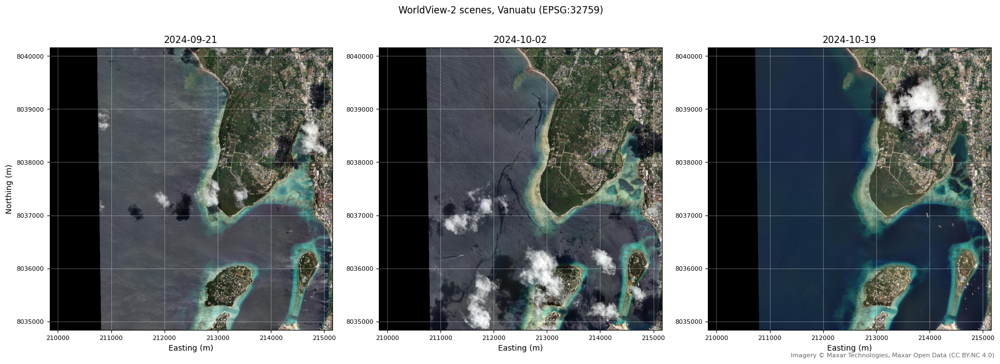

In [6]:
import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

PREVIEW_PX = 1200
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, len(SCENES), figsize=(18, 6.5))

for ax, (scene, tiff_path) in zip(axes, SCENES.items()):
    with rasterio.open(tiff_path) as src:
        scale = max(src.width, src.height) / PREVIEW_PX
        out_h = max(int(src.height / scale), 1)
        out_w = max(int(src.width / scale), 1)
        ov = src.read([1, 2, 3], out_shape=(3, out_h, out_w),
                      resampling=Resampling.average)
        b, crs, gsd = src.bounds, src.crs, abs(src.transform.a)
        print(f"{scene}: {src.width} x {src.height} px | GSD {gsd:.2f} m | {crs}")

    ax.imshow(np.moveaxis(ov, 0, -1), extent=(b.left, b.right, b.bottom, b.top))
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=8)
    ax.grid(color="white", alpha=0.3)
    ax.set_title(scene)
    ax.set_xlabel("Easting (m)")

axes[0].set_ylabel("Northing (m)")
fig.suptitle(f"WorldView-2 scenes, Vanuatu ({crs})")
fig.text(0.99, 0.01, "Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0)",
         ha="right", fontsize=8, color="0.4")
plt.tight_layout()
fig.savefig("figures/scene_overview.jpg", dpi=110, pil_kwargs={"quality": 85})
plt.show()
plt.close(fig)

![Scene overview](figures/scene_overview.jpg)

*Figure 1. WorldView-2 scenes over Port Vila, September–October 2024.
Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0).*

## 5. Settings
`CENTRE` is the middle of the vessel. Use EPSG:32701 `(x, y)` read from the overview or QGIS, or EPSG:4326 `(lon, lat)`.

- `UPSCALE = 2` helps if the boat is short (< ~20 px ≈ 8–10 m at 0.41–0.53 m GSD).
- `CONF = 0.10` is deliberately low for exploration; report at 0.25 to match the DOTA tests.
- **Control test:** also run once with `CENTRE` on empty water. Any detections there are false positives (whitecaps, glint).

## 6. Run detection

Each scene is read row by row from the remote COG and cut into 512 × 512 px
tiles with 128 px overlap. Tiles that are mostly no-data are skipped.
Detections are then:
1. filtered by size: 8–400 m long, length/width ≤ 8;
2. de-duplicated across overlapping tiles: of two boxes overlapping by ≥ 50%
   of the smaller box's area, the lower-confidence one is dropped.

**Parameters**
- `UPSCALE = 1` runs at native resolution. `UPSCALE = 2` can help with short
  boats (under ~20 px), at four times the compute.
- `CONF = 0.30` is the confidence threshold. Lower values add many false
  positives over open water (whitecaps, sun glint).
- `LIMIT_ROWS = 3` runs a quick test on the top strip only.

**Model:** YOLO11-OBB [n/s/m/l/x] (Ultralytics), fine-tuned by the authors on
DOTA v1.5 [all 16 classes / ship class only]. The weights (`best.pt`) are not
included in this repository.

In [7]:
import json
from pathlib import Path

import torch
from PIL import Image, ImageDraw
from rasterio.windows import Window
from shapely.geometry import Polygon, mapping
from shapely.strtree import STRtree
from tqdm.auto import tqdm
from ultralytics import YOLO

# Fallback for the second upload method
if MODEL_PATH is None and os.path.exists("/content/best.pt"):
    MODEL_PATH = "/content/best.pt"

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(MODEL_PATH)

UPSCALE = 1            # 1 = native resolution
TILE = 512             # model input size (px)
OVERLAP = 128          # tile overlap (px)
CONF = 0.30            # confidence threshold
MERGE_OVERLAP = 0.5    # overlap (fraction of smaller box) above which duplicates merge
BATCH = 8              # tiles per model call; lower if GPU memory runs out
MIN_LEN_M, MAX_LEN_M, MAX_ASPECT = 8, 400, 8
LIMIT_ROWS = None      # e.g. 3 for a quick test, None = full tile
PREVIEW_PX = 4000      # full-res overview, saved locally only
FIGURE_PX = 1600       # downsized figure committed to the repo

OUT_DIR = Path("/content/ship_detection/maxar_three_scenes")
RESULTS_DIR = Path("results")
for d in (OUT_DIR, RESULTS_DIR, Path("figures")):
    d.mkdir(parents=True, exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [8]:
def rect_dims(poly):
    """Length and width (m) of the polygon's minimum rotated rectangle."""
    xy = np.array(poly.minimum_rotated_rectangle.exterior.coords)
    sides = np.hypot(*np.diff(xy, axis=0).T)[:2]
    return float(max(sides)), float(max(min(sides), 1e-6))


def detect_tile(tiff_path, upscale=1, conf=0.30, tag="run"):
    with rasterio.open(tiff_path) as src:
        T, crs = src.transform, src.crs
        W, H = src.width, src.height
        gsd = abs(T.a)

        ns = int(round(TILE / upscale))         # native px covered by one model tile
        scale = ns / TILE
        step_px = TILE - OVERLAP                # step in model pixels
        step_nat = int(round(step_px * scale))  # step in native pixels
        Ws = int(round(W / scale))              # strip width in model pixels
        rows = list(range(0, max(H - (ns - step_nat), 1), step_nat))
        xs = list(range(0, max(Ws - OVERLAP, 1), step_px))
        if LIMIT_ROWS:
            rows = rows[:LIMIT_ROWS]
        resamp = Resampling.average if scale > 1 else Resampling.bilinear
        print(f"{tag}: GSD {gsd:.2f} m | {W}x{H} px | {crs} | "
              f"{len(rows) * len(xs)} model tiles")

        dets, batch, meta = [], [], []

        def flush():
            if not batch:
                return
            res = model.predict(batch, imgsz=TILE, conf=conf, device=device, verbose=False)
            for r, (x0, r0) in zip(res, meta):
                if r.obb is None or len(r.obb) == 0:
                    continue
                for pts, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.conf.cpu().numpy()):
                    # model px -> native px -> map coordinates
                    dets.append((Polygon([T * ((x0 + x) * scale, r0 + y * scale)
                                          for x, y in pts]), float(c)))
            batch.clear()
            meta.clear()

        for r0 in tqdm(rows, desc=tag):
            hh = min(ns, H - r0)
            strip = src.read([1, 2, 3], window=Window(0, r0, W, hh),
                             out_shape=(3, max(int(round(hh / scale)), 1), Ws),
                             resampling=resamp)       # one remote read per row
            strip = np.moveaxis(strip, 0, -1)
            for x0 in xs:
                tile = strip[:, x0:x0 + TILE]
                if tile.shape[0] < TILE or tile.shape[1] < TILE:
                    pad = np.zeros((TILE, TILE, 3), np.uint8)
                    pad[:tile.shape[0], :tile.shape[1]] = tile
                    tile = pad
                if (tile.max(-1) == 0).mean() > 0.5:  # skip mostly no-data tiles
                    continue
                # Ultralytics treats numpy arrays as BGR (OpenCV order)
                batch.append(np.ascontiguousarray(tile[:, :, ::-1]))
                meta.append((x0, r0))
                if len(batch) == BATCH:
                    flush()
        flush()
        n_raw = len(dets)

        # Size and shape filter
        kept_size = []
        for p, c in dets:
            L, Wd = rect_dims(p)
            if MIN_LEN_M <= L <= MAX_LEN_M and L / Wd <= MAX_ASPECT:
                kept_size.append((p, c))
        dets = sorted(kept_size, key=lambda d: d[1], reverse=True)

        # Merge duplicates from overlapping tiles. Greedy, highest confidence first.
        # Overlap is intersection / smaller area. STRtree.query returns indices (Shapely 2).
        geoms = [d[0] for d in dets]
        tree = STRtree(geoms)
        dead = np.zeros(len(dets), bool)
        for i, g in enumerate(geoms):
            if dead[i]:
                continue
            for j in tree.query(g):
                if j > i and not dead[j] and \
                        g.intersection(geoms[j]).area / min(g.area, geoms[j].area) >= MERGE_OVERLAP:
                    dead[j] = True
        kept = [dets[i] for i in range(len(dets)) if not dead[i]]
        print(f"{tag}: raw {n_raw} | after size filter {len(dets)} | after merge {len(kept)}")

        # GeoJSON in the scene's projected CRS. The "crs" member is non-standard
        # under RFC 7946 but is read by QGIS and GDAL.
        features = []
        for i, (poly, c) in enumerate(kept):
            L, Wd = rect_dims(poly)
            features.append({"type": "Feature", "geometry": mapping(poly),
                             "properties": {"id": i, "conf": round(c, 3),
                                            "length_m": round(L, 1),
                                            "width_m": round(Wd, 1), "scene": tag}})
        gj = RESULTS_DIR / f"detections_{tag}.geojson"
        gj.write_text(json.dumps({"type": "FeatureCollection",
                                  "crs": {"type": "name", "properties": {"name": crs.to_string()}},
                                  "features": features}))

        # Full-res overview with boxes, saved locally (not committed)
        k = min(1.0, PREVIEW_PX / max(W, H))
        ov = src.read([1, 2, 3], out_shape=(3, int(H * k), int(W * k)),
                      resampling=Resampling.average)

    inv = ~T
    img = Image.fromarray(np.ascontiguousarray(np.moveaxis(ov, 0, -1)))
    draw = ImageDraw.Draw(img)
    for poly, _ in kept:
        pts = [(px * k, py * k) for px, py in (inv * xy for xy in poly.exterior.coords)]
        draw.polygon(pts, outline=(255, 40, 40), width=2)
    img.save(OUT_DIR / f"detections_{tag}.jpg", quality=90)

    # Downsized figure for the repo. Boxes would be ~3 px here, so mark centroids.
    f = FIGURE_PX / max(img.size)
    fig_img = img.resize((int(img.width * f), int(img.height * f)), Image.LANCZOS)
    draw = ImageDraw.Draw(fig_img)
    for poly, _ in kept:
        cx, cy = inv * poly.centroid.coords[0]
        cx, cy = cx * k * f, cy * k * f
        draw.ellipse((cx - 6, cy - 6, cx + 6, cy + 6), outline=(255, 40, 40), width=2)
    draw.text((8, fig_img.height - 18),
              "Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0)",
              fill=(255, 255, 255))
    fig_img.save(f"figures/detections_{tag}.jpg", quality=85)

    return features

In [9]:
all_features = {}
for scene, tiff_path in SCENES.items():
    tag = f"{scene}_up{UPSCALE}_c{CONF}"
    all_features[scene] = detect_tile(tiff_path, UPSCALE, CONF, tag)

for scene, feats in all_features.items():
    print(f"{scene}: {len(feats)} detections")

2024-09-21_up1_c0.3: GSD 0.31 m | 17408x17408 px | EPSG:32759 | 2025 model tiles


2024-09-21_up1_c0.3:   0%|          | 0/45 [00:00<?, ?it/s]

2024-09-21_up1_c0.3: raw 74 | after size filter 74 | after merge 49
2024-10-02_up1_c0.3: GSD 0.31 m | 17408x17408 px | EPSG:32759 | 2025 model tiles


2024-10-02_up1_c0.3:   0%|          | 0/45 [00:00<?, ?it/s]

2024-10-02_up1_c0.3: raw 80 | after size filter 79 | after merge 50
2024-10-19_up1_c0.3: GSD 0.31 m | 17408x17408 px | EPSG:32759 | 2025 model tiles


2024-10-19_up1_c0.3:   0%|          | 0/45 [00:00<?, ?it/s]

2024-10-19_up1_c0.3: raw 133 | after size filter 120 | after merge 71
2024-09-21: 49 detections
2024-10-02: 50 detections
2024-10-19: 71 detections


## References

**Imagery**
- Maxar Technologies. *Maxar Open Data Program: Vanuatu Earthquake, December 2024.*
  https://www.maxar.com/open-data. Licensed under
  [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/).

**Model**
- Jocher, G. & Qiu, J. (2024). *Ultralytics YOLO11* (version 11.0.0).
  https://github.com/ultralytics/ultralytics. Licensed under AGPL-3.0.

**Training data**
- Xia, G.-S., Bai, X., Ding, J., Zhu, Z., Belongie, S., Luo, J., Datcu, M.,
  Pelillo, M. & Zhang, L. (2018). DOTA: A large-scale dataset for object
  detection in aerial images. *Proceedings of the IEEE Conference on Computer
  Vision and Pattern Recognition (CVPR)*, 3974–3983.
- Ding, J., Xue, N., Xia, G.-S., Bai, X., Yang, W., Yang, M. Y., Belongie, S.,
  Luo, J., Datcu, M., Pelillo, M. & Zhang, L. (2021). Object detection in aerial
  images: A large-scale benchmark and challenges. *IEEE Transactions on Pattern
  Analysis and Machine Intelligence*, 44(11), 7778–7796.

**Software**
GDAL, rasterio, Shapely, NumPy, Pillow, Matplotlib, PyTorch.

## 7. (Optional) Copy results to Drive
Saves the PNGs and GeoJSONs next to the model, so they survive the Colab session and the group can open them in QGIS.

In [ ]:
!pip install adjustText

## 8. Detection maps for the Port Vila AOI

Detections whose centroid falls inside the AOI polygon, drawn over the imagery
with their confidence scores. Labels are spaced with adjustText.

In [11]:
!pip install -q adjustText

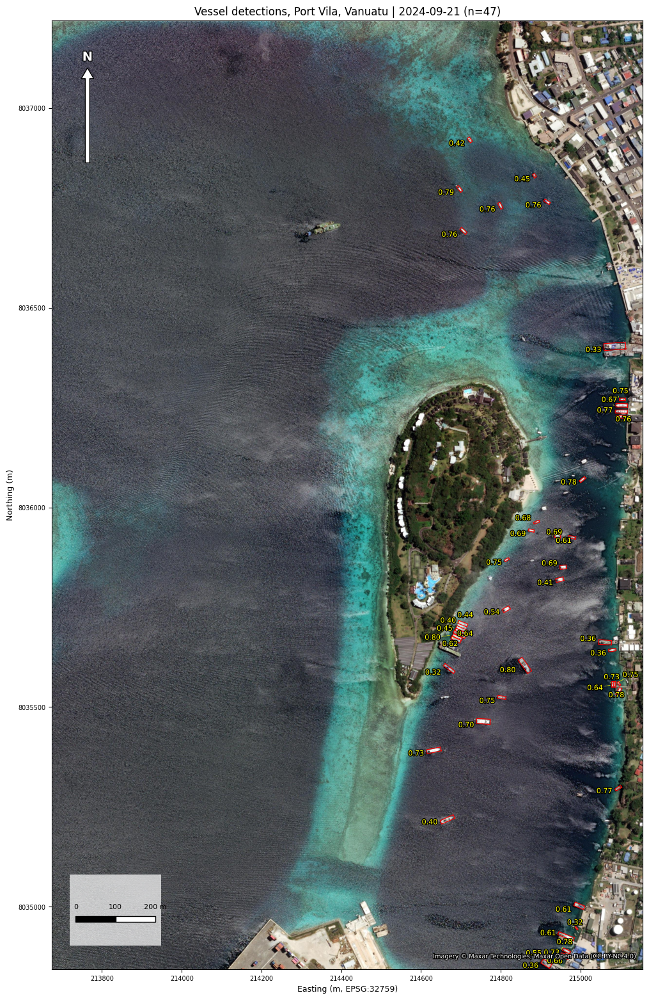

2024-09-21: 47 detections inside the AOI


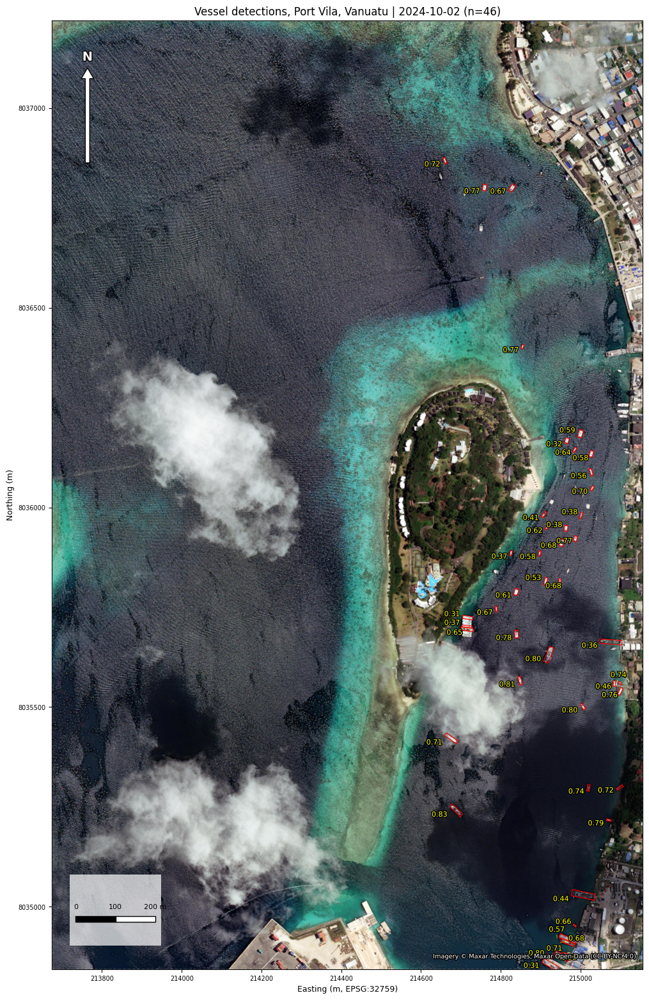

2024-10-02: 46 detections inside the AOI


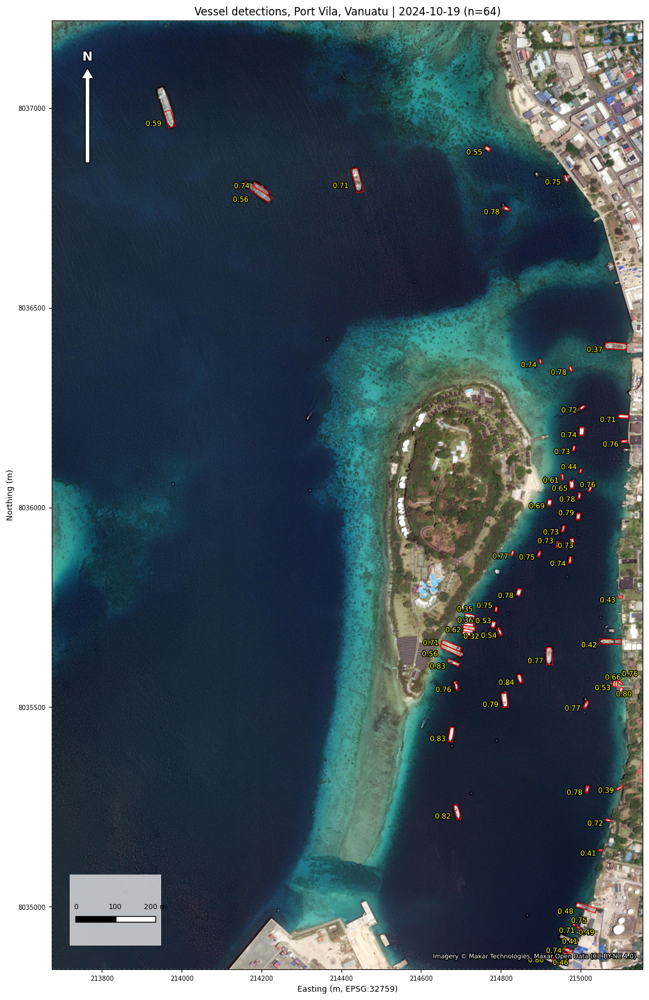

2024-10-19: 64 detections inside the AOI


In [12]:
import geopandas as gpd
import matplotlib.patheffects as pe
from adjustText import adjust_text
from matplotlib.patches import Rectangle
from rasterio.windows import from_bounds
from shapely.geometry import Point, shape

MAX_PX = 3000          # max imagery size (px) on the long side
DPI_PRINT = 300        # local PNG for the report (not committed)
DPI_REPO = 150         # JPEG committed to figures/
SHOW_LABELS = True

aoi = gpd.read_file(AOI_FILE)
if aoi.crs is None:
    raise ValueError("The AOI GeoJSON has no CRS defined.")

HALO = [pe.withStroke(linewidth=2, foreground="black")]
ATTRIBUTION = "Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0)"


def add_scale_bar(ax, left, bottom, width_m, height_m):
    nice = [100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]
    bar = min(nice, key=lambda n: abs(n - width_m / 5))
    x0, y0 = left + 0.04 * width_m, bottom + 0.05 * height_m
    h = 0.006 * height_m
    ax.add_patch(Rectangle((x0 - 0.01 * width_m, y0 - 0.025 * height_m),
                           bar + 0.02 * width_m, 0.075 * height_m,
                           facecolor="white", alpha=0.7, zorder=5))
    ax.add_patch(Rectangle((x0, y0), bar / 2, h, facecolor="black",
                           edgecolor="black", zorder=6))
    ax.add_patch(Rectangle((x0 + bar / 2, y0), bar / 2, h, facecolor="white",
                           edgecolor="black", zorder=6))
    for val, label in [(0, "0"), (bar / 2, f"{bar // 2:,}"), (bar, f"{bar:,} m")]:
        ax.text(x0 + val, y0 + 2 * h, label, ha="center", va="bottom",
                fontsize=8, zorder=6)


def add_north_arrow(ax, x=0.06):
    # Points to grid north (UTM). Convergence at Port Vila is under 1 degree.
    ax.annotate("", xy=(x, 0.95), xytext=(x, 0.85), xycoords="axes fraction",
                arrowprops=dict(facecolor="white", edgecolor="black",
                                width=5, headwidth=14), zorder=6)
    ax.text(x, 0.955, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=14, fontweight="bold", color="white",
            path_effects=HALO, zorder=6)


def create_detection_map(tiff_path, scene, features, tag):
    with rasterio.open(tiff_path) as src:
        crs_name = src.crs.to_string()
        aoi_geom = aoi.to_crs(src.crs).geometry.union_all()
        aoi_left, aoi_bottom, aoi_right, aoi_top = aoi_geom.bounds
        width_m, height_m = aoi_right - aoi_left, aoi_top - aoi_bottom

        # Clip the read window to the raster footprint
        left, bottom = max(aoi_left, src.bounds.left), max(aoi_bottom, src.bounds.bottom)
        right, top = min(aoi_right, src.bounds.right), min(aoi_top, src.bounds.top)
        if left >= right or bottom >= top:
            raise ValueError(f"{scene}: AOI does not overlap the raster. Check CRS.")

        window = from_bounds(left, bottom, right, top, transform=src.transform)
        window = window.round_offsets().round_lengths().intersection(
            Window(0, 0, src.width, src.height))
        win_h, win_w = int(window.height), int(window.width)
        k = min(1.0, MAX_PX / max(win_w, win_h))
        img = src.read([1, 2, 3], window=window,
                       out_shape=(3, max(int(win_h * k), 1), max(int(win_w * k), 1)),
                       resampling=Resampling.average)

        wt = src.window_transform(window)
        img_extent = (wt.c, wt.c + wt.a * win_w, wt.f + wt.e * win_h, wt.f)

    fig, ax = plt.subplots(figsize=(12, 12 * height_m / width_m))
    ax.imshow(np.moveaxis(img, 0, -1), extent=img_extent, origin="upper")
    ax.set_xlim(aoi_left, aoi_right)
    ax.set_ylim(aoi_bottom, aoi_top)

    # AOI outline
    for part in getattr(aoi_geom, "geoms", [aoi_geom]):
        ax.plot(*part.exterior.xy, color="white", linewidth=1, linestyle="--")

    # Detections inside the AOI polygon
    n_drawn, texts = 0, []
    for f in features:
        poly = shape(f["geometry"])
        if not aoi_geom.contains(poly.centroid):
            continue
        x, y = poly.exterior.xy
        ax.plot(x, y, color="red", linewidth=0.8)
        n_drawn += 1
        if SHOW_LABELS:
            texts.append(ax.text(min(x) - width_m * 0.003, np.mean(y),
                                 f"{f['properties']['conf']:.2f}", color="yellow",
                                 fontsize=8, ha="right", va="center",
                                 path_effects=HALO))
    if texts:
        adjust_text(texts, ax=ax,
                    only_move={"text": "xy", "static": "xy", "explode": "xy", "pull": "xy"},
                    arrowprops=dict(arrowstyle="-", color="yellow", lw=0.5))

    add_scale_bar(ax, aoi_left, aoi_bottom, width_m, height_m)
    add_north_arrow(ax)

    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=7)
    ax.set_xlabel(f"Easting (m, {crs_name})", fontsize=9)
    ax.set_ylabel("Northing (m)", fontsize=9)
    ax.set_title(f"Vessel detections, Port Vila, Vanuatu | {scene} (n={n_drawn})",
                 fontsize=12)
    ax.text(0.99, 0.01, ATTRIBUTION, transform=ax.transAxes, ha="right",
            va="bottom", fontsize=7, color="white", path_effects=HALO, zorder=6)

    fig.savefig(OUT_DIR / f"map_{tag}.png", dpi=DPI_PRINT, bbox_inches="tight")
    fig.savefig(f"figures/map_{tag}.jpg", dpi=DPI_REPO, bbox_inches="tight",
                pil_kwargs={"quality": 85})
    plt.show()
    plt.close(fig)
    print(f"{scene}: {n_drawn} detections inside the AOI")


for scene, tiff_path in SCENES.items():
    create_detection_map(tiff_path, scene, all_features[scene],
                         tag=f"{scene}_AOI_up{UPSCALE}_c{CONF}")

![Map 2024-09-21](figures/map_2024-09-21_AOI_up1_c0.3.jpg)
![Map 2024-10-02](figures/map_2024-10-02_AOI_up1_c0.3.jpg)
![Map 2024-10-19](figures/map_2024-10-19_AOI_up1_c0.3.jpg)

*Figure 3. Vessel detections (red boxes, confidence in yellow) inside the Port
Vila AOI (dashed outline). Projected coordinates in WGS 84 / UTM zone 59S.
The north arrow shows grid north, within 1° of true north here.
Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0).*

## 9. Save outputs (optional, Colab only)

Copies the full-resolution maps and overviews (`OUT_DIR`) and the detection
GeoJSONs (`results/`) to Google Drive. Without Drive access, the files are
zipped and downloaded instead. The repository already contains the GeoJSONs
and downsized figures, so this step is only needed for the full-resolution
outputs.

In [13]:
import shutil

SAVE_TO_DRIVE = True
DRIVE_OUT = Path("/content/drive/MyDrive/maxar_inference_results")

files_to_save = [f for f in list(OUT_DIR.glob("*")) + list(RESULTS_DIR.glob("*.geojson"))
                 if f.is_file()]

try:
    if not SAVE_TO_DRIVE:
        raise RuntimeError
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_OUT.mkdir(parents=True, exist_ok=True)
    for f in files_to_save:
        shutil.copy2(f, DRIVE_OUT / f.name)
    print(f"Copied {len(files_to_save)} files to {DRIVE_OUT}")
except Exception:
    bundle = Path("/content/maxar_inference_results")
    bundle.mkdir(exist_ok=True)
    for f in files_to_save:
        shutil.copy2(f, bundle / f.name)
    zip_path = shutil.make_archive(str(bundle), "zip", bundle)
    print(f"Saved {len(files_to_save)} files to {zip_path}")
    try:
        from google.colab import files
        files.download(zip_path)
    except ImportError:
        pass

Mounted at /content/drive
Copied 9 files to /content/drive/MyDrive/maxar_inference_results


### Scene metadata

In [ ]:
import rasterio

print("--- SCENE BOUNDS & CRS ---")

for SCENE, TIFF_PATH in SCENES.items():
    with rasterio.open(TIFF_PATH) as src:
        b = src.bounds

        center_x = (b.left + b.right) / 2
        center_y = (b.bottom + b.top) / 2

        print(f"\nScene: {SCENE}")
        print(f"CRS: {src.crs}")
        print(f"X (Easting) Range:  {b.left:.1f} to {b.right:.1f}")
        print(f"Y (Northing) Range: {b.bottom:.1f} to {b.top:.1f}")
        print(
            f"Scene Center (x, y): "
            f"({center_x:.1f}, {center_y:.1f})"
        )


--- SCENE BOUNDS & CRS ---

Scene: 2024-09-21
CRS: EPSG:32759
X (Easting) Range:  209843.8 to 215156.2
Y (Northing) Range: 8034843.8 to 8040156.2
Scene Center (x, y): (212500.0, 8037500.0)

Scene: 2024-10-02
CRS: EPSG:32759
X (Easting) Range:  209843.8 to 215156.2
Y (Northing) Range: 8034843.8 to 8040156.2
Scene Center (x, y): (212500.0, 8037500.0)

Scene: 2024-10-19
CRS: EPSG:32759
X (Easting) Range:  209843.8 to 215156.2
Y (Northing) Range: 8034843.8 to 8040156.2
Scene Center (x, y): (212500.0, 8037500.0)


In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


THIS IS THE DENSITY MAP USED IN THE PRESENTATION

## 10. Vessel density on water

Detections whose centroid falls on land (`LAND_FILE`) are dropped. The rest are
counted on a regular grid and normalised by the water area in each cell:

$$
d = \frac{\sum w \cdot n}{\sum w \cdot f_{\text{water}}} \cdot \frac{U^2}{A_{\text{cell}}}
$$

where $n$ is the detection count, $f_{\text{water}}$ the water fraction of the
cell (from a 5 m land/water mask), $w$ an optional Gaussian weight
(`SMOOTH_M`; 0 = no smoothing) and $U$ the reporting unit (`UNIT_M`).
Cells with less than `MIN_WATER_FRAC` water are not shown, because dividing by
a small water fraction inflates single detections along the coast.
All three scenes share one colour scale.

Land polygons: [source, as in section 3].

Outputs: `results/detections_<scene>_water_only.geojson`, plus a density GeoTIFF
per scene (kept locally).

In [20]:
from matplotlib.colors import ListedColormap
from rasterio.features import rasterize
from rasterio.transform import from_origin, from_bounds as tf_from_bounds
from scipy.ndimage import binary_dilation, gaussian_filter, label, zoom

# Mask settings
MIN_AREA_M2 = 0        # 0 = apply the land polygon exactly (no filling of small gaps)
BOAT_BUFFER_M = 0      # 0 = drop every detection on land; e.g. 20 keeps boats at wharf edges

# Density settings
CELL_M = 300           # counting grid (m); must be a multiple of MASK_M
UNIT_M = CELL_M        # reporting unit; 1000 gives detections per km²
SMOOTH_M = 0           # Gaussian radius (m); 0 = no smoothing
MASK_M = 5             # land/water mask resolution (m)
MIN_WATER_FRAC = 0.25  # hide cells with less water than this (limits coastal inflation)
VMAX = None            # fixed colour-scale max, or None for the shared percentile below
VMAX_PCT = 99
HEAT_ALPHA = 0.7
CMAP = "RdYlBu_r"      # blue (low) -> yellow -> red (high)
SHOW_POINTS = True
SHOW_IMAGERY = True


def small_components(m, n_px):
    """Boolean mask of connected components smaller than n_px."""
    lab, n = label(m)
    if n == 0:
        return np.zeros_like(m)
    small = np.bincount(lab.ravel()) < n_px
    small[0] = False
    return small[lab]


def compute_density(tiff_path, scene, features, tag):
    with rasterio.open(tiff_path) as src:
        left, bottom, right, top = src.bounds
        crs_name = src.crs.to_string()
        width_m, height_m = right - left, top - bottom
        nx = max(int(round(width_m / CELL_M)), 1)
        ny = max(int(round(height_m / CELL_M)), 1)
        f = max(int(round(CELL_M / MASK_M)), 1)
        mw, mh = nx * f, ny * f
        rgb_m = src.read([1, 2, 3], out_shape=(3, mh, mw), resampling=Resampling.average)
        k = min(1.0, MAX_PX / max(src.width, src.height))
        ov = src.read([1, 2, 3], out_shape=(3, int(src.height * k), int(src.width * k)),
                      resampling=Resampling.average)

    # Land/water mask
    valid = rgb_m.max(0) > 0
    mask_px = width_m / mw
    land = gpd.read_file(LAND_FILE)
    if land.crs is None:
        land = land.set_crs("EPSG:4326")   # GeoJSON default (RFC 7946)
    land = land.to_crs(crs_name)
    masked_out = rasterize([(g, 1) for g in land.geometry if g is not None and not g.is_empty],
                           out_shape=(mh, mw),
                           transform=tf_from_bounds(left, bottom, right, top, mw, mh),
                           fill=0, dtype="uint8").astype(bool)
    assert masked_out.any(), "Land polygon doesn't overlap the scene. Check its CRS."

    water = valid & ~masked_out
    if MIN_AREA_M2 > 0:
        min_px = max(int(MIN_AREA_M2 / mask_px**2), 1)
        water = valid & (water | small_components(valid & ~water, min_px))

    # Drop detections on land
    pts = np.array([[*shape(ft["geometry"]).centroid.coords[0]] for ft in features],
                   dtype=float).reshape(-1, 2)
    col = ((pts[:, 0] - left) / width_m * mw).astype(int).clip(0, mw - 1)
    row = ((top - pts[:, 1]) / height_m * mh).astype(int).clip(0, mh - 1)
    keep_zone = (binary_dilation(water, iterations=max(int(round(BOAT_BUFFER_M / mask_px)), 1))
                 if BOAT_BUFFER_M > 0 else water)
    on_water = keep_zone[row, col]
    pts_w = pts[on_water]
    print(f"{scene}: land {masked_out.mean() * 100:.1f}% of tile | "
          f"{on_water.sum()} of {len(pts)} detections on water")

    (RESULTS_DIR / f"detections_{tag}_water_only.geojson").write_text(json.dumps(
        {"type": "FeatureCollection",
         "crs": {"type": "name", "properties": {"name": crs_name}},
         "features": [ft for ft, ok in zip(features, on_water) if ok]}))

    # Density per UNIT_M square of water
    cell_w, cell_h = width_m / nx, height_m / ny
    counts, _, _ = np.histogram2d(pts_w[:, 1], pts_w[:, 0], bins=[ny, nx],
                                  range=[[bottom, top], [left, right]])
    counts = np.flipud(counts)                           # row 0 = north
    water_f = water.reshape(ny, f, nx, f).mean(axis=(1, 3))
    sig = SMOOTH_M / CELL_M
    num = gaussian_filter(counts, sig, mode="constant")
    den = gaussian_filter(water_f, sig, mode="constant")
    ok = den >= MIN_WATER_FRAC
    dens = np.where(ok, num / np.maximum(den, MIN_WATER_FRAC), np.nan)
    dens *= UNIT_M**2 / (cell_w * cell_h)

    with rasterio.open(OUT_DIR / f"density_water_{tag}.tif", "w", driver="GTiff",
                       height=ny, width=nx, count=1, dtype="float32", crs=crs_name,
                       transform=from_origin(left, top, cell_w, cell_h), nodata=-9999) as dst:
        dst.write(np.where(ok, dens, -9999).astype("float32"), 1)

    # Upsample to mask resolution for display; grid_mode aligns cell edges
    dens_px = zoom(np.nan_to_num(dens), f, order=1, grid_mode=True, mode="nearest")
    ok_px = zoom(ok.astype(float), f, order=0, grid_mode=True, mode="nearest") > 0.5

    return {"scene": scene, "ov": ov, "extent": (left, right, bottom, top),
            "left": left, "bottom": bottom, "width_m": width_m, "height_m": height_m,
            "crs_name": crs_name, "water": water, "pts": pts, "on_water": on_water,
            "pts_w": pts_w, "dens": dens,
            "heat": np.ma.masked_where(~(water & ok_px), dens_px)}


density = [compute_density(tiff_path, scene, all_features[scene],
                           tag=f"{scene}_up{UPSCALE}_c{CONF}")
           for scene, tiff_path in SCENES.items()]

all_dens = np.concatenate([d["dens"][np.isfinite(d["dens"])] for d in density])
vmax = VMAX if VMAX is not None else max(np.percentile(all_dens, VMAX_PCT), 1e-9)
print(f"Shared colour scale: 0–{vmax:.1f} detections per {UNIT_M} m square "
      f"(peak {all_dens.max():.1f})")

2024-09-21: land 24.5% of tile | 38 of 49 detections on water
2024-10-02: land 24.5% of tile | 42 of 50 detections on water
2024-10-19: land 24.5% of tile | 56 of 71 detections on water
Shared colour scale: 0–7.6 detections per 300 m square (peak 12.2)


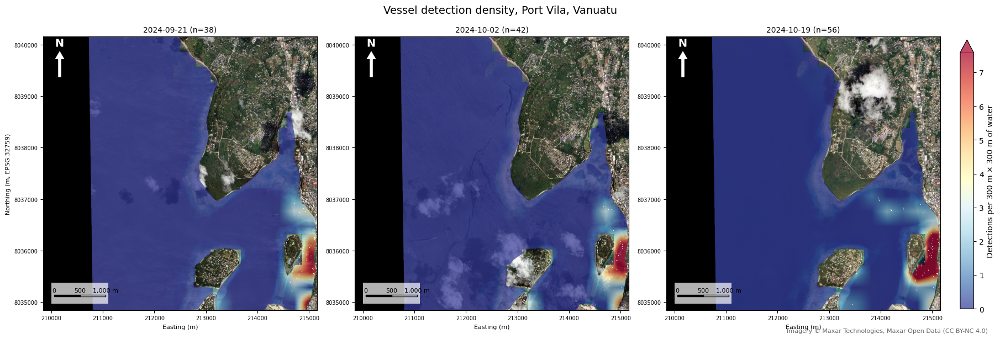

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, d in zip(axes, density):
    if SHOW_IMAGERY:
        ax.imshow(np.moveaxis(d["ov"], 0, -1), extent=d["extent"])
    else:
        ax.set_facecolor("#d9d9d9")
    im = ax.imshow(d["heat"], extent=d["extent"], cmap=CMAP, vmin=0, vmax=vmax,
                   alpha=HEAT_ALPHA, interpolation="bilinear")
    if SHOW_POINTS:
        ax.plot(d["pts_w"][:, 0], d["pts_w"][:, 1], ".", color="white",
                ms=2, mew=0, alpha=0.8)
    add_scale_bar(ax, d["left"], d["bottom"], d["width_m"], d["height_m"])
    add_north_arrow(ax)
    ax.set_title(f"{d['scene']} (n={len(d['pts_w'])})", fontsize=10)
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=7)
    ax.set_xlabel("Easting (m)", fontsize=8)
axes[0].set_ylabel(f"Northing (m, {density[0]['crs_name']})", fontsize=8)

fig.colorbar(im, ax=axes, location="right", fraction=0.015, pad=0.02,
             extend="max").set_label(f"Detections per {UNIT_M} m × {UNIT_M} m of water",
                                     fontsize=10)
fig.suptitle("Vessel detection density, Port Vila, Vanuatu", fontsize=14)
fig.text(0.99, 0.005, ATTRIBUTION, ha="right", fontsize=8, color="0.4")
fig.savefig(OUT_DIR / "density_panels.png", dpi=DPI_PRINT)
fig.savefig("figures/density_panels.jpg", dpi=DPI_REPO, pil_kwargs={"quality": 85})
plt.show()
plt.close(fig)

![Density maps](figures/density_panels.jpg)

*Figure 4. Detections per 300 m × 300 m of water, on a shared colour scale
(99th percentile across all scenes). Cells with less than 25% water are not
shown. North arrows show grid north. Imagery © Maxar Technologies,
Maxar Open Data (CC BY-NC 4.0).

### Land mask check
Red = masked out as land. Cyan crosses = detections dropped because their
centroid falls on land.

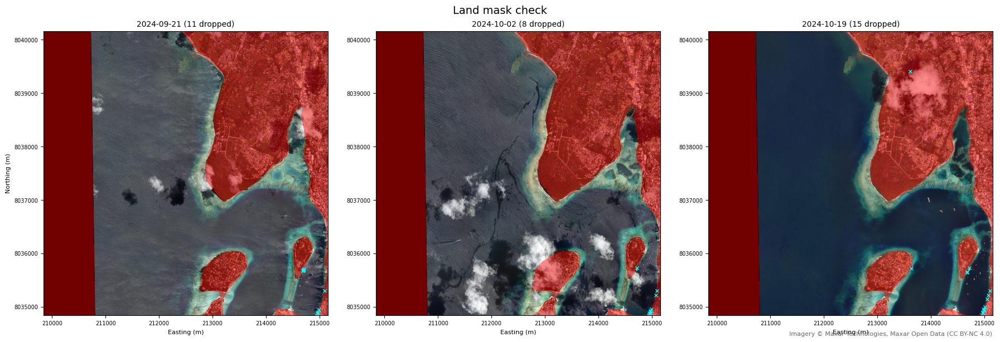

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, d in zip(axes, density):
    ax.imshow(np.moveaxis(d["ov"], 0, -1), extent=d["extent"])
    ax.imshow(np.ma.masked_where(d["water"], np.ones(d["water"].shape)), extent=d["extent"],
              cmap=ListedColormap(["red"]), alpha=0.45, interpolation="nearest")
    ax.plot(d["pts"][~d["on_water"], 0], d["pts"][~d["on_water"], 1], "x",
            color="cyan", ms=4)
    ax.set_title(f"{d['scene']} ({(~d['on_water']).sum()} dropped)", fontsize=10)
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=7)
    ax.set_xlabel("Easting (m)", fontsize=8)
axes[0].set_ylabel("Northing (m)", fontsize=8)
fig.suptitle("Land mask check", fontsize=14)
fig.text(0.99, 0.005, ATTRIBUTION, ha="right", fontsize=8, color="0.4")
fig.savefig("figures/maskcheck_panels.jpg", dpi=DPI_REPO, pil_kwargs={"quality": 85})
plt.show()
plt.close(fig)

![Land mask check](figures/maskcheck_panels.jpg)

*Figure 4. Land mask (red) and detections dropped as on land (cyan).
Imagery © Maxar Technologies, Maxar Open Data (CC BY-NC 4.0).